# Comparación climática: Medellín y Kampala

Actividad S30 (EA3) de Analítica de Datos. Integrantes: Cristian Piedrahita y Santiago Londoño.

## A. Predicción, periodo común y variables

**Predicción previa:** Esperaba que Medellín y Kampala, por estar cerca del ecuador y a altitudes parecidas, tuvieran temperaturas máximas similares a lo largo del año, y que Medellín fuera la ciudad más lluviosa.

La comparación usa el periodo común de ambas ciudades y las variables de temperatura máxima, temperatura mínima y precipitación diaria. Los metadatos, la fuente específica y su fecha de descarga se muestran a continuación desde variables del notebook.

### Fuentes y periodo común

| Ciudad | Fuente | Enlace | Periodo común | Frecuencia | Variables y unidades |
|---|---|---|---|---|---|
| Medellín, Colombia | Open-Meteo, Historical Weather API | https://open-meteo.com/en/docs/historical-weather-api | Del 1 de enero de 2025 (2025-01-01) al 31 de diciembre de 2025 (2025-12-31) | Diaria | Temperatura máxima (°C), temperatura mínima (°C), precipitación (mm) |
| Kampala, Uganda | Open-Meteo, Historical Weather API | https://open-meteo.com/en/docs/historical-weather-api | Del 1 de enero de 2025 (2025-01-01) al 31 de diciembre de 2025 (2025-12-31) | Diaria | Temperatura máxima (°C), temperatura mínima (°C), precipitación (mm) |

Referencias adicionales: Zippenfennig, P. (2023). Open-Meteo.com Weather API. https://doi.org/10.5281/zenodo.7970649 · Hersbach et al. (2020). The ERA5 global reanalysis. https://doi.org/10.1002/qj.3803 · Consulta y descarga: 14 de noviembre de 2026. Los datos son de reanálisis/modelo, no de estaciones.

In [1]:
from pathlib import Path

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PERIODO_INICIO = pd.Timestamp("2025-01-01")
PERIODO_FIN = pd.Timestamp("2025-12-31")
VARIABLES = {
    "temperature_2m_max (°C)": "Temperatura máxima (°C)",
    "temperature_2m_min (°C)": "Temperatura mínima (°C)",
    "precipitation_sum (mm)": "Precipitación diaria (mm)",
}
ARCHIVOS = {
    "Medellín": Path("datos") / "medellin.csv",
    "Kampala": Path("datos") / "kampala.csv",
}

print(f"Periodo común: {PERIODO_INICIO.date()} a {PERIODO_FIN.date()}")
print("Variables comparadas:", ", ".join(VARIABLES.values()))

Periodo común: 2025-01-01 a 2025-12-31
Variables comparadas: Temperatura máxima (°C), Temperatura mínima (°C), Precipitación diaria (mm)


In [2]:
from IPython.display import Markdown, display

FECHA_DESCARGA = pd.Timestamp("2026-11-14")
URL_FUENTE_OPEN_METEO = (
    "https://open-meteo.com/en/docs/historical-weather-api"
)
METADATOS_CIUDADES = {
    "Medellín, Colombia": {
        "latitud": 6.22,
        "longitud": -75.55,
        "elevacion_m": 1476,
        "zona_horaria": "America/Bogota",
    },
    "Kampala, Uganda": {
        "latitud": 0.39,
        "longitud": 32.58,
        "elevacion_m": 1174,
        "zona_horaria": "Africa/Kampala",
    },
}

filas_metadatos = []
for ciudad, metadatos in METADATOS_CIUDADES.items():
    direccion_longitud = "O" if metadatos["longitud"] < 0 else "E"
    filas_metadatos.append(
        f"| {ciudad} | "
        f"{metadatos['latitud']:.2f}° N, "
        f"{abs(metadatos['longitud']):.2f}° {direccion_longitud} | "
        f"{metadatos['elevacion_m']:.0f} m | "
        f"`{metadatos['zona_horaria']}` |"
    )

display(
    Markdown(
        f"**Periodo común:** {PERIODO_INICIO.strftime('%d/%m/%Y')} a "
        f"{PERIODO_FIN.strftime('%d/%m/%Y')}, con observaciones diarias. "
        "Las temperaturas se expresan en °C y la precipitación en mm.\n\n"
        "| Ciudad | Coordenadas | Elevación | Zona horaria local |\n"
        "|---|---:|---:|---|\n"
        + "\n".join(filas_metadatos)
        + f"\n\n**Fuente:** [Open-Meteo Historical Weather API]"
        f"({URL_FUENTE_OPEN_METEO}), datos de reanálisis/modelo, no de "
        "estaciones meteorológicas. "
        f"**Fecha de descarga:** {FECHA_DESCARGA.day} de noviembre de "
        f"{FECHA_DESCARGA.year}."
    )
)

**Periodo común:** 01/01/2025 a 31/12/2025, con observaciones diarias. Las temperaturas se expresan en °C y la precipitación en mm.

| Ciudad | Coordenadas | Elevación | Zona horaria local |
|---|---:|---:|---|
| Medellín, Colombia | 6.22° N, 75.55° O | 1476 m | `America/Bogota` |
| Kampala, Uganda | 0.39° N, 32.58° E | 1174 m | `Africa/Kampala` |

**Fuente:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), datos de reanálisis/modelo, no de estaciones meteorológicas. **Fecha de descarga:** 14 de noviembre de 2026.

## B. Carga y revisión de los datos

Se leen los CSV saltando sus tres líneas de metadatos. Las fechas se convierten a `datetime64[ns]` y las mediciones a `float`; se informa de faltantes y duplicados sin rellenar ni descartar filas. El conteo válido considera fechas dentro del periodo común y filas con las tres mediciones disponibles.

In [3]:
datos = {}
columnas_medicion = list(VARIABLES)
columnas_requeridas = ["time", *columnas_medicion]
resumen_calidad = {}
dias_esperados = len(pd.date_range(PERIODO_INICIO, PERIODO_FIN, freq="D"))

for ciudad, ruta in ARCHIVOS.items():
    df = pd.read_csv(ruta, skiprows=3)
    df["time"] = pd.to_datetime(df["time"], errors="raise").astype("datetime64[ns]")
    for columna in columnas_medicion:
        df[columna] = pd.to_numeric(df[columna], errors="raise").astype(float)
    datos[ciudad] = df

    en_periodo = df["time"].between(PERIODO_INICIO, PERIODO_FIN)
    validas = en_periodo & df[columnas_requeridas].notna().all(axis=1)
    observaciones_validas = int(validas.sum())
    faltantes_por_columna = df.isna().sum()
    fechas_duplicadas = int(df.duplicated(subset="time").sum())
    resumen_calidad[ciudad] = {
        "observaciones_validas": observaciones_validas,
        "dias_esperados": dias_esperados,
        "faltantes": int(df[columnas_requeridas].isna().sum().sum()),
        "fechas_duplicadas": fechas_duplicadas,
    }
    print(f"\n{ciudad}")
    print("Columnas:", df.columns.tolist())
    print("Primeras filas:")
    display(df.head())
    print("Dimensiones:", df.shape)
    print("Fecha inicial:", df["time"].min())
    print("Fecha final:", df["time"].max())
    print("Faltantes por columna:\n", df.isna().sum().to_string())
    print("Fechas duplicadas:", fechas_duplicadas)
    print("Tipos:\n", df.dtypes.to_string())
    print("Observaciones válidas en el periodo común:", observaciones_validas)


Medellín
Columnas: ['time', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)']
Primeras filas:


,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm)
0,2025-01-01,26.1,15.5,13.5
1,2025-01-02,26.4,16.0,10.0
2,2025-01-03,23.5,15.6,8.8
3,2025-01-04,25.9,15.5,19.4
4,2025-01-05,25.5,16.4,20.2


Dimensiones: (365, 4)
Fecha inicial: 2025-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Faltantes por columna:
 time                       0
temperature_2m_max (°C)    0
temperature_2m_min (°C)    0
precipitation_sum (mm)     0
Fechas duplicadas: 0
Tipos:
 time                       datetime64[ns]
temperature_2m_max (°C)           float64
temperature_2m_min (°C)           float64
precipitation_sum (mm)            float64
Observaciones válidas en el periodo común: 365

Kampala
Columnas: ['time', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)']
Primeras filas:


,time,temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm)
0,2025-01-01,28.6,18.1,0.1
1,2025-01-02,26.6,16.9,1.0
2,2025-01-03,27.3,16.9,1.3
3,2025-01-04,28.7,17.9,0.1
4,2025-01-05,29.6,17.9,0.0


Dimensiones: (365, 4)
Fecha inicial: 2025-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Faltantes por columna:
 time                       0
temperature_2m_max (°C)    0
temperature_2m_min (°C)    0
precipitation_sum (mm)     0
Fechas duplicadas: 0
Tipos:
 time                       datetime64[ns]
temperature_2m_max (°C)           float64
temperature_2m_min (°C)           float64
precipitation_sum (mm)            float64
Observaciones válidas en el periodo común: 365


## C. Análisis con NumPy

Se construyen arrays NumPy para las tres mediciones de cada ciudad. El corte muestra los primeros siete días del periodo común de cada ciudad. El broadcasting centra los promedios mensuales de temperatura máxima respecto al promedio compartido de las ciudades.

In [4]:
UMBRAL_LLUVIA_MM = 1.0
UMBRAL_CALOR_C = 30.0
arrays = {}
fechas_comunes = {}
mascaras_lluvia = {}
mascaras_calor = {}
estadisticas = {}
promedios_mensuales_tmax = []

for ciudad, df in datos.items():
    periodo = df.loc[df["time"].between(PERIODO_INICIO, PERIODO_FIN)]
    fechas_comunes[ciudad] = periodo["time"].to_numpy(dtype="datetime64[ns]")
    arrays[ciudad] = {
        columna: periodo[columna].to_numpy(dtype=float)
        for columna in columnas_medicion
    }
    tmax = arrays[ciudad]["temperature_2m_max (°C)"]
    tmin = arrays[ciudad]["temperature_2m_min (°C)"]
    precipitacion = arrays[ciudad]["precipitation_sum (mm)"]
    mascaras_lluvia[ciudad] = np.isfinite(precipitacion) & (
        precipitacion >= UMBRAL_LLUVIA_MM
    )
    mascaras_calor[ciudad] = np.isfinite(tmax) & (tmax >= UMBRAL_CALOR_C)

    print(f"\n{ciudad}: corte de los primeros siete días")
    display(
        pd.DataFrame(
            {
                "fecha": fechas_comunes[ciudad][:7],
                "temperatura máxima (°C)": tmax[:7],
                "temperatura mínima (°C)": tmin[:7],
                "precipitación (mm)": precipitacion[:7],
            }
        )
    )

    estadisticas[ciudad] = {
        "Temperatura máxima promedio (°C)": np.mean(tmax),
        "Temperatura máxima mínima (°C)": np.min(tmax),
        "Temperatura máxima mayor (°C)": np.max(tmax),
        "Temperatura mínima promedio (°C)": np.mean(tmin),
        "Temperatura mínima menor (°C)": np.min(tmin),
        "Temperatura mínima mayor (°C)": np.max(tmin),
        "Precipitación total (mm)": np.sum(precipitacion),
        f"Días lluviosos (≥ {UMBRAL_LLUVIA_MM:g} mm)": np.count_nonzero(
            mascaras_lluvia[ciudad]
        ),
        f"Días calientes (tmax ≥ {UMBRAL_CALOR_C:g} °C)": np.count_nonzero(
            mascaras_calor[ciudad]
        ),
    }
    meses = periodo["time"].dt.month.to_numpy()
    promedios_mensuales_tmax.append(
        np.array([np.mean(tmax[meses == mes]) for mes in range(1, 13)])
    )

print("\nEstadísticas descriptivas por ciudad:")
display(pd.DataFrame.from_dict(estadisticas, orient="index"))
display(
    Markdown(
        f"Se definió día lluvioso como precipitación diaria ≥ "
        f"{UMBRAL_LLUVIA_MM:g} mm y día caliente como temperatura máxima ≥ "
        f"{UMBRAL_CALOR_C:g} °C. Ambos umbrales se aplicaron por igual "
        "a las dos ciudades."
    )
)

matriz_mensual_tmax = np.vstack(promedios_mensuales_tmax)
promedio_compartido_por_mes = matriz_mensual_tmax.mean(axis=0)
anomalias_mensuales_tmax = matriz_mensual_tmax - promedio_compartido_por_mes
print(
    "\nBroadcasting: matriz ciudad × mes",
    matriz_mensual_tmax.shape,
    "menos vector de promedios mensuales",
    promedio_compartido_por_mes.shape,
    "=",
    anomalias_mensuales_tmax.shape,
)
display(
    pd.DataFrame(
        anomalias_mensuales_tmax,
        index=list(datos),
        columns=[f"Mes {mes}" for mes in range(1, 13)],
    )
)


Medellín: corte de los primeros siete días


,fecha,temperatura máxima (°C),temperatura mínima (°C),precipitación (mm)
0,2025-01-01,26.1,15.5,13.5
1,2025-01-02,26.4,16.0,10.0
2,2025-01-03,23.5,15.6,8.8
3,2025-01-04,25.9,15.5,19.4
4,2025-01-05,25.5,16.4,20.2
5,2025-01-06,27.3,16.6,0.7
6,2025-01-07,27.3,16.9,8.5



Kampala: corte de los primeros siete días


,fecha,temperatura máxima (°C),temperatura mínima (°C),precipitación (mm)
0,2025-01-01,28.6,18.1,0.1
1,2025-01-02,26.6,16.9,1.0
2,2025-01-03,27.3,16.9,1.3
3,2025-01-04,28.7,17.9,0.1
4,2025-01-05,29.6,17.9,0.0
5,2025-01-06,27.5,16.1,2.3
6,2025-01-07,26.6,17.4,3.2



Estadísticas descriptivas por ciudad:


,Temperatura máxima promedio (°C),Temperatura máxima mínima (°C),Temperatura máxima mayor (°C),Temperatura mínima promedio (°C),Temperatura mínima menor (°C),Temperatura mínima mayor (°C),Precipitación total (mm),Días lluviosos (≥ 1 mm),Días calientes (tmax ≥ 30 °C)
Medellín,26.953425,21.7,30.0,16.549589,14.6,18.1,2193.9,267,1
Kampala,26.834795,21.4,35.2,17.916438,14.9,20.5,1207.9,217,18


Se definió día lluvioso como precipitación diaria ≥ 1 mm y día caliente como temperatura máxima ≥ 30 °C. Ambos umbrales se aplicaron por igual a las dos ciudades.


Broadcasting: matriz ciudad × mes (2, 12) menos vector de promedios mensuales (12,) = (2, 12)


,Mes 1,Mes 2,Mes 3,Mes 4,Mes 5,Mes 6,Mes 7,Mes 8,Mes 9,Mes 10,Mes 11,Mes 12
Medellín,-0.272581,-1.653571,-0.467742,0.606667,0.769355,0.698333,1.429032,0.496774,-0.381667,-0.224194,-0.32,-0.122581
Kampala,0.272581,1.653571,0.467742,-0.606667,-0.769355,-0.698333,-1.429032,-0.496774,0.381667,0.224194,0.32,0.122581


In [5]:
indice_ciudad = {ciudad: indice for indice, ciudad in enumerate(datos)}
indice_febrero = 1
indice_julio = 6
desviacion_febrero_medellin = anomalias_mensuales_tmax[
    indice_ciudad["Medellín"], indice_febrero
]
desviacion_febrero_kampala = anomalias_mensuales_tmax[
    indice_ciudad["Kampala"], indice_febrero
]
desviacion_julio_medellin = anomalias_mensuales_tmax[
    indice_ciudad["Medellín"], indice_julio
]
desviacion_julio_kampala = anomalias_mensuales_tmax[
    indice_ciudad["Kampala"], indice_julio
]

display(
    Markdown(
        "Cada valor de la matriz es la desviación de la temperatura máxima "
        "mensual de una ciudad respecto al promedio de las dos ciudades "
        "en ese mismo mes. "
        f"En febrero, Medellín se desvía {desviacion_febrero_medellin:.2f} °C "
        f"y Kampala {desviacion_febrero_kampala:.2f} °C; "
        f"en julio, Medellín se desvía {desviacion_julio_medellin:.2f} °C "
        f"y Kampala {desviacion_julio_kampala:.2f} °C. "
        "Como solo hay dos ciudades, sus desviaciones respecto a la media "
        "compartida son iguales en magnitud y opuestas en signo. "
        "Esto describe diferencias relativas y no sus causas."
    )
)

Cada valor de la matriz es la desviación de la temperatura máxima mensual de una ciudad respecto al promedio de las dos ciudades en ese mismo mes. En febrero, Medellín se desvía -1.65 °C y Kampala 1.65 °C; en julio, Medellín se desvía 1.43 °C y Kampala -1.43 °C. Como solo hay dos ciudades, sus desviaciones respecto a la media compartida son iguales en magnitud y opuestas en signo. Esto describe diferencias relativas y no sus causas.

## D. Gráficas comparativas

Las tres gráficas comparan los mismos días del periodo común. Después de cada figura, el código genera una breve lectura basada en los valores calculados y señala qué no permite concluir.

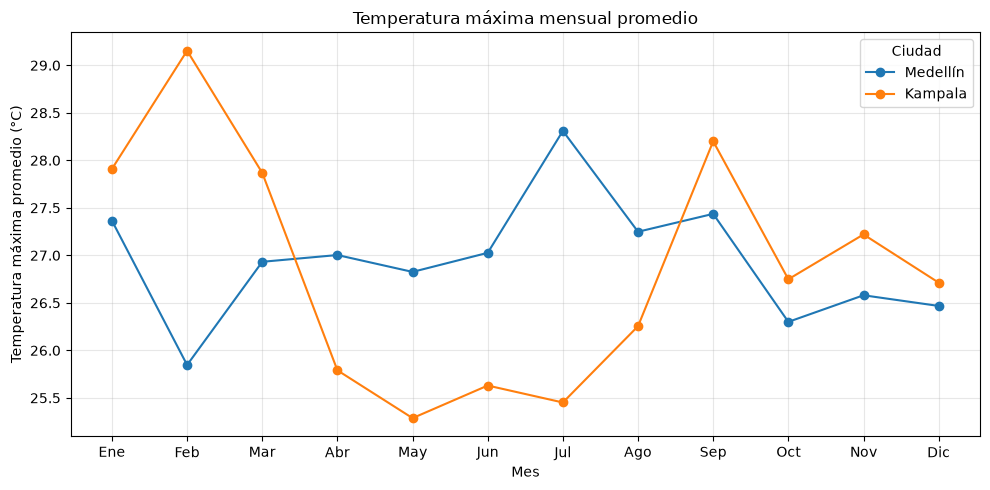

El promedio mensual de temperatura máxima alcanzó su valor mayor en Jul para Medellín (28.3 °C) y en Feb para Kampala (29.2 °C). La línea describe promedios mensuales y no permite inferir causas de las diferencias observadas.

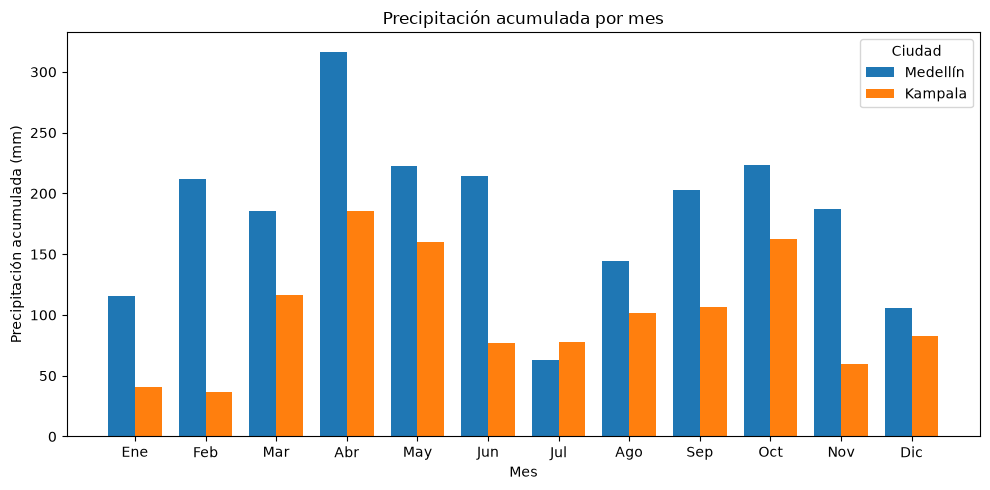

El mayor acumulado mensual se registró en Abr para Medellín (316.7 mm) y en Abr para Kampala (185.3 mm). Los acumulados mensuales no muestran la distribución de la lluvia dentro de cada mes ni establecen causalidad.

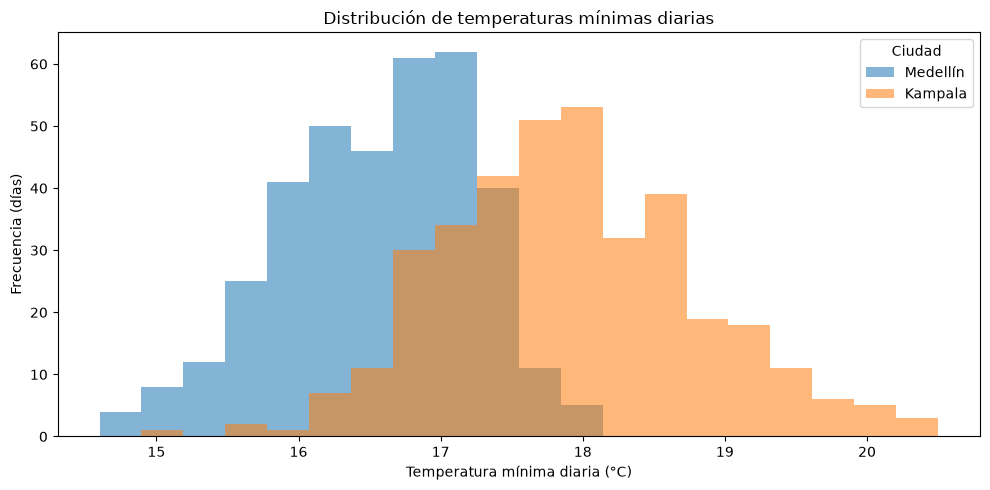

Las medianas de temperatura mínima diaria fueron 16.6 °C en Medellín y 17.9 °C en Kampala; el histograma permite comparar sus frecuencias. La figura no conserva el orden de las fechas ni explica las causas de las diferencias.

In [6]:
from IPython.display import Markdown

nombres_meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
]
meses = np.arange(1, 13)
resumenes_mensuales = {}

for ciudad, df in datos.items():
    periodo_grafica = df.loc[
        df["time"].between(PERIODO_INICIO, PERIODO_FIN)
    ].copy()
    periodo_grafica["mes"] = periodo_grafica["time"].dt.month
    resumenes_mensuales[ciudad] = periodo_grafica.groupby("mes")

tmax_mensual = pd.DataFrame(
    {
        ciudad: grupos["temperature_2m_max (°C)"].mean()
        for ciudad, grupos in resumenes_mensuales.items()
    }
).reindex(meses)

fig, ax = plt.subplots(figsize=(10, 5))
for ciudad in datos:
    ax.plot(meses, tmax_mensual[ciudad], marker="o", label=ciudad)
ax.set_title("Temperatura máxima mensual promedio")
ax.set_xlabel("Mes")
ax.set_ylabel("Temperatura máxima promedio (°C)")
ax.set_xticks(meses, nombres_meses)
ax.legend(title="Ciudad")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

mes_pico_medellin = int(tmax_mensual["Medellín"].idxmax())
mes_pico_kampala = int(tmax_mensual["Kampala"].idxmax())
display(
    Markdown(
        f"El promedio mensual de temperatura máxima alcanzó su valor mayor "
        f"en {nombres_meses[mes_pico_medellin - 1]} para Medellín "
        f"({tmax_mensual.loc[mes_pico_medellin, 'Medellín']:.1f} °C) y en "
        f"{nombres_meses[mes_pico_kampala - 1]} para Kampala "
        f"({tmax_mensual.loc[mes_pico_kampala, 'Kampala']:.1f} °C). "
        "La línea describe promedios mensuales y no permite inferir causas "
        "de las diferencias observadas."
    )
)

precipitacion_mensual = pd.DataFrame(
    {
        ciudad: grupos["precipitation_sum (mm)"].sum()
        for ciudad, grupos in resumenes_mensuales.items()
    }
).reindex(meses)

ancho = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(meses - ancho / 2, precipitacion_mensual["Medellín"], ancho, label="Medellín")
ax.bar(meses + ancho / 2, precipitacion_mensual["Kampala"], ancho, label="Kampala")
ax.set_title("Precipitación acumulada por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Precipitación acumulada (mm)")
ax.set_xticks(meses, nombres_meses)
ax.legend(title="Ciudad")
fig.tight_layout()
plt.show()

mes_lluvioso_medellin = int(precipitacion_mensual["Medellín"].idxmax())
mes_lluvioso_kampala = int(precipitacion_mensual["Kampala"].idxmax())
display(
    Markdown(
        f"El mayor acumulado mensual se registró en "
        f"{nombres_meses[mes_lluvioso_medellin - 1]} para Medellín "
        f"({precipitacion_mensual.loc[mes_lluvioso_medellin, 'Medellín']:.1f} mm) "
        f"y en {nombres_meses[mes_lluvioso_kampala - 1]} para Kampala "
        f"({precipitacion_mensual.loc[mes_lluvioso_kampala, 'Kampala']:.1f} mm). "
        "Los acumulados mensuales no muestran la distribución de la lluvia "
        "dentro de cada mes ni establecen causalidad."
    )
)

temperaturas_minimas = {
    ciudad: arrays[ciudad]["temperature_2m_min (°C)"] for ciudad in datos
}
limites_bins = np.histogram_bin_edges(
    np.concatenate(list(temperaturas_minimas.values())),
    bins="auto",
)
fig, ax = plt.subplots(figsize=(10, 5))
for ciudad, valores in temperaturas_minimas.items():
    ax.hist(valores, bins=limites_bins, alpha=0.55, label=ciudad)
ax.set_title("Distribución de temperaturas mínimas diarias")
ax.set_xlabel("Temperatura mínima diaria (°C)")
ax.set_ylabel("Frecuencia (días)")
ax.legend(title="Ciudad")
fig.tight_layout()
plt.show()

mediana_tmin_medellin = np.median(temperaturas_minimas["Medellín"])
mediana_tmin_kampala = np.median(temperaturas_minimas["Kampala"])
display(
    Markdown(
        f"Las medianas de temperatura mínima diaria fueron "
        f"{mediana_tmin_medellin:.1f} °C en Medellín y "
        f"{mediana_tmin_kampala:.1f} °C en Kampala; el histograma permite "
        "comparar sus frecuencias. La figura no conserva el orden de las "
        "fechas ni explica las causas de las diferencias."
    )
)

## E. Interpretación de resultados

Los hallazgos y el contexto de la comparación se generan a partir de las variables calculadas en las secciones anteriores. Se describen diferencias observadas sin atribuir causalidad.

In [7]:
from IPython.display import Markdown

nombres_meses_completos = [
    "enero", "febrero", "marzo", "abril", "mayo", "junio",
    "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre",
]
key_dias_lluviosos = f"Días lluviosos (≥ {UMBRAL_LLUVIA_MM:g} mm)"
key_dias_calor = f"Días calientes (tmax ≥ {UMBRAL_CALOR_C:g} °C)"

promedio_tmax_medellin = estadisticas["Medellín"][
    "Temperatura máxima promedio (°C)"
]
promedio_tmax_kampala = estadisticas["Kampala"][
    "Temperatura máxima promedio (°C)"
]
diferencia_promedios_tmax = abs(
    promedio_tmax_medellin - promedio_tmax_kampala
)
mes_pico_tmax_medellin = int(tmax_mensual["Medellín"].idxmax())
mes_pico_tmax_kampala = int(tmax_mensual["Kampala"].idxmax())
diferencias_tmax_mensuales = (
    tmax_mensual["Medellín"] - tmax_mensual["Kampala"]
).abs()
mes_mayor_diferencia_tmax = int(diferencias_tmax_mensuales.idxmax())
mayor_diferencia_tmax_mensual = float(
    diferencias_tmax_mensuales.loc[mes_mayor_diferencia_tmax]
)

total_precipitacion_medellin = estadisticas["Medellín"][
    "Precipitación total (mm)"
]
total_precipitacion_kampala = estadisticas["Kampala"][
    "Precipitación total (mm)"
]
dias_lluviosos_medellin = estadisticas["Medellín"][key_dias_lluviosos]
dias_lluviosos_kampala = estadisticas["Kampala"][key_dias_lluviosos]
mes_lluvioso_medellin = int(precipitacion_mensual["Medellín"].idxmax())
mes_lluvioso_kampala = int(precipitacion_mensual["Kampala"].idxmax())
mes_seco_medellin = int(precipitacion_mensual["Medellín"].idxmin())
total_mes_seco_medellin = float(
    precipitacion_mensual.loc[mes_seco_medellin, "Medellín"]
)

promedio_tmin_medellin = estadisticas["Medellín"][
    "Temperatura mínima promedio (°C)"
]
promedio_tmin_kampala = estadisticas["Kampala"][
    "Temperatura mínima promedio (°C)"
]
mediana_tmin_medellin = float(
    np.median(arrays["Medellín"]["temperature_2m_min (°C)"])
)
mediana_tmin_kampala = float(
    np.median(arrays["Kampala"]["temperature_2m_min (°C)"])
)
dias_calor_medellin = estadisticas["Medellín"][key_dias_calor]
dias_calor_kampala = estadisticas["Kampala"][key_dias_calor]

def formato_conteo_dias(conteo):
    unidad = "día" if conteo == 1 else "días"
    return f"{conteo} {unidad}"

calidad_medellin = resumen_calidad["Medellín"]
calidad_kampala = resumen_calidad["Kampala"]
fechas_medellin = datos["Medellín"].loc[
    datos["Medellín"]["time"].between(PERIODO_INICIO, PERIODO_FIN), "time"
].to_numpy(dtype="datetime64[ns]")
fechas_kampala = datos["Kampala"].loc[
    datos["Kampala"]["time"].between(PERIODO_INICIO, PERIODO_FIN), "time"
].to_numpy(dtype="datetime64[ns]")
fechas_compartidas = np.intersect1d(fechas_medellin, fechas_kampala)

if (
    calidad_medellin["faltantes"] == 0
    and calidad_kampala["faltantes"] == 0
    and calidad_medellin["fechas_duplicadas"] == 0
    and calidad_kampala["fechas_duplicadas"] == 0
):
    texto_calidad = (
        "No hubo faltantes ni duplicados, por lo que no se eliminó ni "
        "se rellenó ningún día. "
    )
else:
    texto_calidad = (
        "No se rellenaron datos ni se eliminaron filas durante la revisión. "
    )

prediccion_lluvia_confirmada = (
    total_precipitacion_medellin > total_precipitacion_kampala
    and dias_lluviosos_medellin > dias_lluviosos_kampala
)
resultado_prediccion_lluvia = (
    "se confirma en el periodo estudiado"
    if prediccion_lluvia_confirmada
    else "no se confirma por ambos indicadores en el periodo estudiado"
)

timezone_medellin = METADATOS_CIUDADES["Medellín, Colombia"]["zona_horaria"]
timezone_kampala = METADATOS_CIUDADES["Kampala, Uganda"]["zona_horaria"]

display(
    Markdown(
        f"- **Similitud (y su matiz estacional) en las temperaturas máximas.** El promedio "
        f"anual de temperatura máxima fue {promedio_tmax_medellin:.1f} °C "
        f"en Medellín y {promedio_tmax_kampala:.1f} °C en Kampala "
        f"(diferencia absoluta de {diferencia_promedios_tmax:.2f} °C). "
        f"El mayor promedio mensual ocurrió en "
        f"{nombres_meses_completos[mes_pico_tmax_medellin - 1]} para Medellín "
        f"({tmax_mensual.loc[mes_pico_tmax_medellin, 'Medellín']:.1f} °C) "
        f"y en {nombres_meses_completos[mes_pico_tmax_kampala - 1]} para "
        f"Kampala ({tmax_mensual.loc[mes_pico_tmax_kampala, 'Kampala']:.1f} °C). "
        f"La mayor diferencia mensual fue en "
        f"{nombres_meses_completos[mes_mayor_diferencia_tmax - 1]} "
        f"({mayor_diferencia_tmax_mensual:.1f} °C), lo que matiza la "
        "similitud de los promedios anuales.\n\n"
        f"- **Precipitación.** El total fue {total_precipitacion_medellin:.1f} mm "
        f"en Medellín y {total_precipitacion_kampala:.1f} mm en Kampala; "
        f"con el umbral de {UMBRAL_LLUVIA_MM:g} mm, hubo "
        f"{dias_lluviosos_medellin} y {dias_lluviosos_kampala} días lluviosos, "
        "respectivamente. El mes más lluvioso fue "
        f"{nombres_meses_completos[mes_lluvioso_medellin - 1]} en Medellín "
        f"({precipitacion_mensual.loc[mes_lluvioso_medellin, 'Medellín']:.1f} mm) "
        f"y {nombres_meses_completos[mes_lluvioso_kampala - 1]} en Kampala "
        f"({precipitacion_mensual.loc[mes_lluvioso_kampala, 'Kampala']:.1f} mm); "
        f"el mes más seco de Medellín fue "
        f"{nombres_meses_completos[mes_seco_medellin - 1]} "
        f"({total_mes_seco_medellin:.1f} mm).\n\n"
        f"- **Temperaturas mínimas y días de calor.** El promedio/mediana "
        f"de temperatura mínima fue {promedio_tmin_medellin:.1f}/"
        f"{mediana_tmin_medellin:.1f} °C en Medellín y "
        f"{promedio_tmin_kampala:.1f}/{mediana_tmin_kampala:.1f} °C en Kampala. "
        f"Con el umbral de calor de {UMBRAL_CALOR_C:g} °C, se contaron "
        f"{formato_conteo_dias(dias_calor_medellin)} en Medellín y "
        f"{formato_conteo_dias(dias_calor_kampala)} en Kampala.\n\n"
        f"- **Cobertura de datos.** Medellín tuvo "
        f"{calidad_medellin['observaciones_validas']} de "
        f"{calidad_medellin['dias_esperados']} observaciones válidas y Kampala "
        f"{calidad_kampala['observaciones_validas']} de "
        f"{calidad_kampala['dias_esperados']}; faltantes: "
        f"{calidad_medellin['faltantes']} y {calidad_kampala['faltantes']}; "
        f"fechas duplicadas: {calidad_medellin['fechas_duplicadas']} y "
        f"{calidad_kampala['fechas_duplicadas']}. "
        f"{texto_calidad}Ambas series comparten {len(fechas_compartidas)} "
        "fechas del periodo común, lo que permite comparar los mismos días.\n\n"
        f"- **Predicción previa.** La predicción de temperaturas máximas "
        f"similares a lo largo del año se cumplió en el promedio anual "
        f"(diferencia de {diferencia_promedios_tmax:.2f} °C), pero no mes a mes: "
        f"la mayor diferencia mensual fue de {mayor_diferencia_tmax_mensual:.1f} °C "
        f"en {nombres_meses_completos[mes_mayor_diferencia_tmax - 1]}, y los meses "
        f"de mayor promedio fueron distintos: "
        f"{nombres_meses_completos[mes_pico_tmax_medellin - 1]} en Medellín y "
        f"{nombres_meses_completos[mes_pico_tmax_kampala - 1]} en Kampala. "
        f"La predicción de que Medellín sería más lluviosa "
        f"{resultado_prediccion_lluvia}.\n\n"
        f"El periodo común fue {PERIODO_INICIO.strftime('%d/%m/%Y')} a "
        f"{PERIODO_FIN.strftime('%d/%m/%Y')}, así que los resultados describen "
        "ese periodo y no establecen patrones de largo plazo. Los días se "
        f"agregan en hora local ({timezone_medellin} y {timezone_kampala}); "
        "sus límites no corresponden al mismo intervalo UTC. Open-Meteo "
        "provee datos de reanálisis/modelo, no mediciones de estaciones. "
        "Estos resultados describen diferencias y no permiten atribuir causalidad."
    )
)

- **Similitud (y su matiz estacional) en las temperaturas máximas.** El promedio anual de temperatura máxima fue 27.0 °C en Medellín y 26.8 °C en Kampala (diferencia absoluta de 0.12 °C). El mayor promedio mensual ocurrió en julio para Medellín (28.3 °C) y en febrero para Kampala (29.2 °C). La mayor diferencia mensual fue en febrero (3.3 °C), lo que matiza la similitud de los promedios anuales.

- **Precipitación.** El total fue 2193.9 mm en Medellín y 1207.9 mm en Kampala; con el umbral de 1 mm, hubo 267 y 217 días lluviosos, respectivamente. El mes más lluvioso fue abril en Medellín (316.7 mm) y abril en Kampala (185.3 mm); el mes más seco de Medellín fue julio (62.9 mm).

- **Temperaturas mínimas y días de calor.** El promedio/mediana de temperatura mínima fue 16.5/16.6 °C en Medellín y 17.9/17.9 °C en Kampala. Con el umbral de calor de 30 °C, se contaron 1 día en Medellín y 18 días en Kampala.

- **Cobertura de datos.** Medellín tuvo 365 de 365 observaciones válidas y Kampala 365 de 365; faltantes: 0 y 0; fechas duplicadas: 0 y 0. No hubo faltantes ni duplicados, por lo que no se eliminó ni se rellenó ningún día. Ambas series comparten 365 fechas del periodo común, lo que permite comparar los mismos días.

- **Predicción previa.** La predicción de temperaturas máximas similares a lo largo del año se cumplió en el promedio anual (diferencia de 0.12 °C), pero no mes a mes: la mayor diferencia mensual fue de 3.3 °C en febrero, y los meses de mayor promedio fueron distintos: julio en Medellín y febrero en Kampala. La predicción de que Medellín sería más lluviosa se confirma en el periodo estudiado.

El periodo común fue 01/01/2025 a 31/12/2025, así que los resultados describen ese periodo y no establecen patrones de largo plazo. Los días se agregan en hora local (America/Bogota y Africa/Kampala); sus límites no corresponden al mismo intervalo UTC. Open-Meteo provee datos de reanálisis/modelo, no mediciones de estaciones. Estos resultados describen diferencias y no permiten atribuir causalidad.

### Respuesta a la pregunta guía: similitud y diferencia

**Similitud (con cifras).** Las dos ciudades tienen una temperatura máxima anual casi igual: 27.0 °C en Medellín y 26.8 °C en Kampala, una diferencia de solo 0.12 °C. Además, ambas tuvieron abril como mes más lluvioso (316.7 mm en Medellín y 185.3 mm en Kampala) y el rango de la temperatura máxima diaria empieza en valores parecidos (21.7 °C en Medellín y 21.4 °C en Kampala).

**Diferencia (con cifras).** Medellín acumuló 2193.9 mm de lluvia frente a 1207.9 mm en Kampala, y tuvo 267 días lluviosos (≥ 1 mm) frente a 217. La temperatura mínima promedio fue 16.5 °C en Medellín y 17.9 °C en Kampala, y los días con temperatura máxima ≥ 30 °C fueron 1 en Medellín y 18 en Kampala.

**Matiz.** Aunque el promedio anual de la temperatura máxima es casi igual, mes a mes no lo es: la mayor diferencia fue en febrero (3.3 °C). Estos resultados describen 2025, con datos modelados, y no permiten atribuir causas.